In [9]:
import pandas as pd
from googleapiclient.discovery import build
from google.colab import userdata

api_key = userdata.get("youtube_api_key")
youtube = build("youtube", "v3", developerKey=api_key)

def get_channel_id_by_handle(handle):
    request = youtube.search().list(
        part="snippet",
        q=handle,
        type="channel",
        maxResults=1
    )
    response = request.execute()
    if response["items"]:
        return response["items"][0]["snippet"]["channelId"]
    raise Exception("Channel not found!")

channel_handle = "@GreenEntertainmentTV"
channel_id = get_channel_id_by_handle(channel_handle)
print(f"Found Channel ID: {channel_id}")

channel_response = youtube.channels().list(
    part="contentDetails",
    id=channel_id
).execute()

uploads_playlist_id = channel_response["items"][0]["contentDetails"]["relatedPlaylists"]["uploads"]

videos = []
playlist_request = youtube.playlistItems().list(
    part="snippet",
    playlistId=uploads_playlist_id,
    maxResults=50
)

while playlist_request:
    playlist_response = playlist_request.execute()
    for item in playlist_response["items"]:
        videos.append({
            "video_id": item["snippet"]["resourceId"]["videoId"],
            "title": item["snippet"]["title"],
            "published_at": item["snippet"]["publishedAt"]
        })
    playlist_request = youtube.playlistItems().list_next(playlist_request, playlist_response)

print(f"Total videos fetched: {len(videos)}")

all_comments = []

for vid in videos:
    video_id = vid["video_id"]
    title = vid["title"]

    try:
        comment_request = youtube.commentThreads().list(
            part="snippet",
            videoId=video_id,
            maxResults=100,
            textFormat="plainText"
        )

        while comment_request:
            comment_response = comment_request.execute()
            for item in comment_response["items"]:
                comment = item["snippet"]["topLevelComment"]["snippet"]["textDisplay"]
                all_comments.append({
                    "video_id": video_id,
                    "video_title": title,
                    "comment": comment
                })

            if len(all_comments) >= 2000:
                break

            comment_request = youtube.commentThreads().list_next(comment_request, comment_response)

    except Exception as e:
        continue

    if len(all_comments) >= 2000:
        break

df_comments = pd.DataFrame(all_comments)
df_comments.to_csv("greentv_youtube_comments.csv", index=False)
print(f"Success! Downloaded {len(df_comments)} comments and saved to 'greentv_youtube_comments.csv'.")

Found Channel ID: UCF2ltLX1dnPa6-L1paPaMzw
Total videos fetched: 20000
Success! Downloaded 2066 comments and saved to 'greentv_youtube_comments.csv'.


In [10]:
import pandas as pd
import re

df = pd.read_csv("greentv_youtube_comments.csv")

original_count = len(df)

df = df.dropna(subset=['comment'])
df['comment'] = df['comment'].astype(str).str.strip()
df = df[df['comment'] != '']
df = df.drop_duplicates(subset=['comment'])

def is_valid_comment(text):
    cleaned = re.sub(r'[^\w\s]', '', text)
    return len(cleaned.strip()) > 0

df = df[df['comment'].apply(is_valid_comment)]

df.to_csv("cleaned_youtube_comments.csv", index=False)

print(f"Original comments count: {original_count}")
print(f"Cleaned comments count: {len(df)}")
print("Success! Cleaned data saved to 'cleaned_youtube_comments.csv'.")

Original comments count: 2066
Cleaned comments count: 1723
Success! Cleaned data saved to 'cleaned_youtube_comments.csv'.


In [11]:
import pandas as pd
from transformers import pipeline

df = pd.read_csv("cleaned_youtube_comments.csv")

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest"
)

label_mapping = {
    "positive": "Positive",
    "neutral": "Neutral",
    "negative": "Negative"
}

def analyze_sentiment(text):
    try:
        truncated_text = str(text)[:512]
        result = sentiment_pipeline(truncated_text)[0]
        label = result['label'].lower()
        return label_mapping.get(label, "Neutral")
    except Exception:
        return "Neutral"

print("Analyzing sentiment for comments... (This may take a minute or two)")
df['sentiment'] = df['comment'].apply(analyze_sentiment)

df.to_csv("sentiment_analyzed_comments.csv", index=False)

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())
print("\nSuccess! Sentiment data saved to 'sentiment_analyzed_comments.csv'.")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

model.safetensors: downloading bytes:           |  0.00B            

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Analyzing sentiment for comments... (This may take a minute or two)

Sentiment Distribution:
sentiment
Neutral     1084
Positive     426
Negative     213
Name: count, dtype: int64

Success! Sentiment data saved to 'sentiment_analyzed_comments.csv'.


/tmp/ipykernel_772/2443050378.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index, y=category_counts.values, palette='Blues_d')


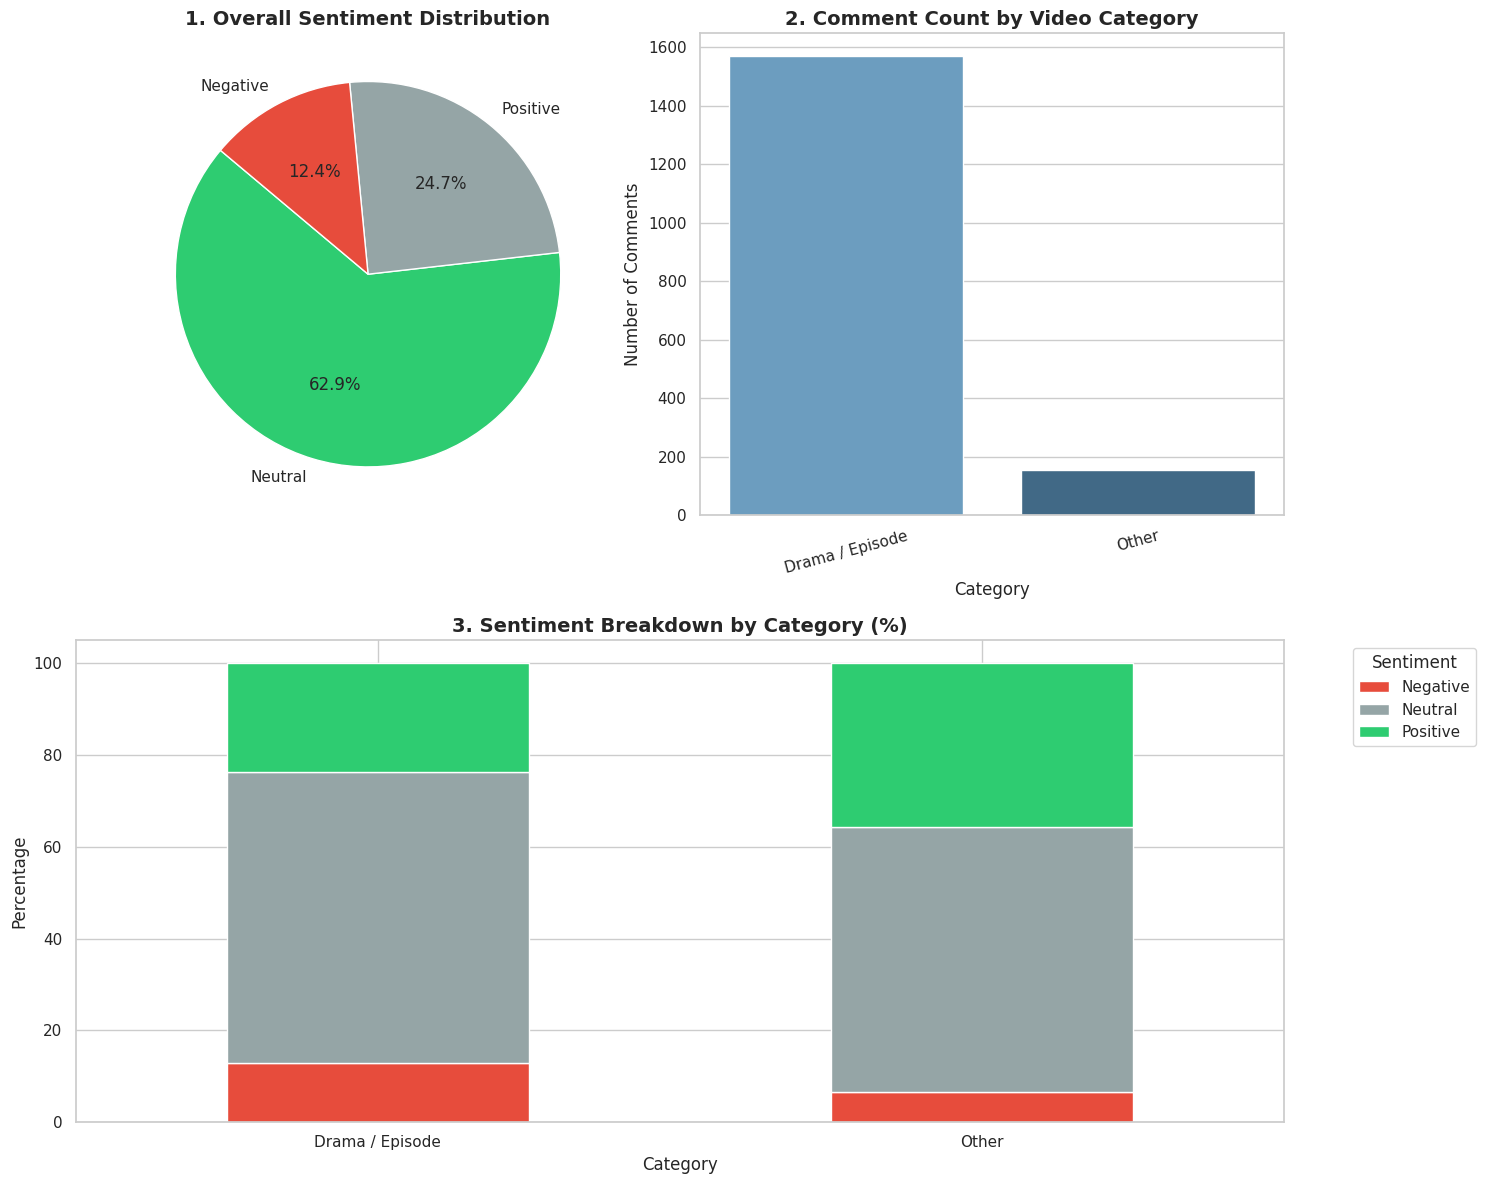


Summary Statistics:
sentiment        Negative  Neutral  Positive   All
category                                          
Drama / Episode       203      995       371  1569
Other                  10       89        55   154
All                   213     1084       426  1723


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sentiment_analyzed_comments.csv")

def categorize_video(title):
    title_lower = str(title).lower()
    if any(keyword in title_lower for keyword in ['ep', 'episode', 'dram']):
        return 'Drama / Episode'
    elif any(keyword in title_lower for keyword in ['teaser', 'promo', 'trailer']):
        return 'Teaser / Promo'
    elif any(keyword in title_lower for keyword in ['ost', 'song', 'music']):
        return 'OST / Music'
    else:
        return 'Other'

df['category'] = df['video_title'].apply(categorize_video)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 12))

plt.subplot(2, 2, 1)
sentiment_counts = df['sentiment'].value_counts()
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    colors=['#2ecc71', '#95a5a6', '#e74c3c'],
    startangle=140
)
plt.title('1. Overall Sentiment Distribution', fontsize=14, fontweight='bold')

plt.subplot(2, 2, 2)
category_counts = df['category'].value_counts()
sns.barplot(x=category_counts.index, y=category_counts.values, palette='Blues_d')
plt.title('2. Comment Count by Video Category', fontsize=14, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Number of Comments')
plt.xticks(rotation=15)

plt.subplot(2, 1, 2)
sentiment_by_cat = pd.crosstab(df['category'], df['sentiment'], normalize='index') * 100
sentiment_by_cat.plot(
    kind='bar',
    stacked=True,
    color=['#e74c3c', '#95a5a6', '#2ecc71'],
    ax=plt.gca()
)
plt.title('3. Sentiment Breakdown by Category (%)', fontsize=14, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("greentv_sentiment_charts.png", dpi=300)
plt.show()

print("\nSummary Statistics:")
print(pd.crosstab(df['category'], df['sentiment'], margins=True))

In [14]:
import pandas as pd

df = pd.read_csv("sentiment_analyzed_comments.csv")

def categorize_video(title):
    title_lower = str(title).lower()
    if any(keyword in title_lower for keyword in ['ep', 'episode', 'dram']):
        return 'Drama / Episode'
    elif any(keyword in title_lower for keyword in ['teaser', 'promo', 'trailer']):
        return 'Teaser / Promo'
    elif any(keyword in title_lower for keyword in ['ost', 'song', 'music']):
        return 'OST / Music'
    else:
        return 'Other'

df['category'] = df['video_title'].apply(categorize_video)

total_comments = len(df)
sentiment_pct = df['sentiment'].value_counts(normalize=True) * 100
cat_sentiment = pd.crosstab(df['category'], df['sentiment'], normalize='index') * 100
cat_counts = df['category'].value_counts()

def get_pct(cat, sentiment_type):
    if cat in cat_sentiment.index and sentiment_type in cat_sentiment.columns:
        return round(cat_sentiment.loc[cat, sentiment_type], 1)
    return 0.0

pos_pct = round(sentiment_pct.get('Positive', 0), 1)
neg_pct = round(sentiment_pct.get('Negative', 0), 1)
neu_pct = round(sentiment_pct.get('Neutral', 0), 1)

print("="*60)
print("          AI-ASSISTED RECOMMENDATION ENGINE OUTPUT          ")
print("="*60)
print(f"\n[DATA SUMMARY]")
print(f"• Total Analyzed Comments: {total_comments}")
print(f"• Overall Sentiment Breakdown: Positive {pos_pct}%, Neutral {neu_pct}%, Negative {neg_pct}%\n")

print("[STRATEGIC RECOMMENDATIONS]")

if 'OST / Music' in cat_sentiment.index:
    ost_pos = get_pct('OST / Music', 'Positive')
    print(f"1. OST & Music Content:")
    print(f"   -> Result: OST/Music content achieved {ost_pos}% positive audience sentiment.")
    print(f"   -> Advice: Continue releasing full original soundtracks and music videos early. OSTs serve as strong emotional drivers and key audience acquisition tools.\n")

if 'Drama / Episode' in cat_sentiment.index:
    drama_pos = get_pct('Drama / Episode', 'Positive')
    drama_neg = get_pct('Drama / Episode', 'Negative')
    print(f"2. Drama Episodes:")
    print(f"   -> Result: Episodes account for the highest volume of user comments ({cat_counts.get('Drama / Episode', 0)} comments), with {drama_pos}% positive and {drama_neg}% negative feedback.")
    print(f"   -> Advice: Monitor negative feedback on episodes specifically for storyline pacing or editing complaints to optimize future content drops.\n")

if 'Teaser / Promo' in cat_sentiment.index:
    teaser_pos = get_pct('Teaser / Promo', 'Positive')
    print(f"3. Teasers & Promos:")
    print(f"   -> Result: Teasers received {teaser_pos}% positive sentiment.")
    print(f"   -> Advice: Maintain short, high-cliffhanger promos to maximize engagement and drive viewership to upcoming episodes.\n")

print("4. Meta Data Exclusion Note:")
print("   -> 'Meta (Facebook/Instagram) data was excluded due to API access restrictions.'")
print("="*60)

          AI-ASSISTED RECOMMENDATION ENGINE OUTPUT          

[DATA SUMMARY]
• Total Analyzed Comments: 1723
• Overall Sentiment Breakdown: Positive 24.7%, Neutral 62.9%, Negative 12.4%

[STRATEGIC RECOMMENDATIONS]
2. Drama Episodes:
   -> Result: Episodes account for the highest volume of user comments (1569 comments), with 23.6% positive and 12.9% negative feedback.
   -> Advice: Monitor negative feedback on episodes specifically for storyline pacing or editing complaints to optimize future content drops.

4. Meta Data Exclusion Note:
   -> 'Meta (Facebook/Instagram) data was excluded due to API access restrictions.'
